# 02 - Feature assessment and modeling decisions

Notebook 01 explored the data. This notebook prepares for the SLA breach model in Phase 5:

1. what each feature in `ticket_features` tells us on its own,
2. which features repeat each other,
3. how to handle missing history at the start of the data,
4. how different the test period is from the training period,

and it ends with a **decision record**: the population, split, features, metrics and baselines for Phase 5, written down before any model is trained so the evaluation cannot be tuned to the results.

**To run:** the database must be running and loaded (see notebook 01).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from opspilot.analysis.data import load_features
from opspilot.analysis.stats import cramers_v, difference_interval, population_stability_index, rank_auc

ROOT = Path.cwd().parent
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titlelocation": "left", "axes.titleweight": "bold",
})
ACCENT, MUTED, HIGHLIGHT = "#2f6690", "#9aa5b1", "#d1495b"


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")


# Proposed modeling window and split. The design document fixes the end
# (exclude the last 14 days) and a time-based split; section 4 checks the start.
MODEL_START = pd.Timestamp("2024-02-01")
TEST_START = pd.Timestamp("2025-07-01")
MODEL_END = pd.Timestamp("2025-12-18")  # exclusive

NUMERIC = [
    "sla_hours", "hour_of_day", "day_of_week", "hours_until_staffed",
    "team_agents", "team_open_at_arrival", "team_open_per_agent", "team_arrivals_prev_24h",
    "subcategory_arrivals_prev_2h", "subcategory_arrivals_prev_24h",
    "team_resolved_prev_30d", "team_breach_rate_prev_30d",
    "subcategory_resolved_prev_90d", "subcategory_breach_rate_prev_90d",
    "description_length",
]
BOOLEAN = ["is_weekend", "is_holiday", "mentions_urgency"]
CATEGORICAL = ["priority", "ticket_type", "category", "subcategory", "assigned_team",
               "academic_period", "requester_type", "channel", "department"]

In [2]:
features = load_features()
labelled = features[features["sla_breached"].notna()].copy()
labelled["sla_breached"] = labelled["sla_breached"].astype(bool)
print(f"{len(features):,} tickets, {len(labelled):,} with a label")

50,295 tickets, 49,242 with a label


## 1. Feature inventory

In [3]:
groups = {
    "submitted": ["priority", "ticket_type", "category", "subcategory", "assigned_team", "requester_type",
                  "channel", "department", "sla_hours"],
    "arrival time": ["hour_of_day", "day_of_week", "is_weekend", "is_holiday", "academic_period", "hours_until_staffed"],
    "workload": ["team_agents", "team_open_at_arrival", "team_open_per_agent", "team_arrivals_prev_24h"],
    "similar tickets": ["subcategory_arrivals_prev_2h", "subcategory_arrivals_prev_24h"],
    "recent outcomes": ["team_resolved_prev_30d", "team_breach_rate_prev_30d",
                        "subcategory_resolved_prev_90d", "subcategory_breach_rate_prev_90d"],
    "description": ["description_length", "mentions_urgency"],
}
inventory = pd.DataFrame(
    [{"feature": f, "group": g, "dtype": str(labelled[f].dtype),
      "missing_pct": round(100 * labelled[f].isna().mean(), 2), "distinct": labelled[f].nunique()}
     for g, names in groups.items() for f in names]
)
assert set(inventory["feature"]) == set(NUMERIC + BOOLEAN + CATEGORICAL)
inventory

,feature,group,dtype,missing_pct,distinct
0,priority,submitted,str,0.00,4
1,ticket_type,submitted,str,0.00,2
2,category,submitted,str,0.00,8
3,subcategory,submitted,str,0.00,29
4,assigned_team,submitted,str,0.00,7
5,requester_type,submitted,str,0.00,3
6,channel,submitted,str,0.00,5
7,department,submitted,str,0.00,10
8,sla_hours,submitted,float64,0.00,5
9,hour_of_day,arrival time,Int64,0.00,24


27 candidate features in six groups. Only the two historical breach rates have missing values (0.04% and 0.09% of labelled tickets), and section 5 shows they are all in January 2024. Every feature is computed from information available when the ticket was created, which the time-travel test in the database test suite checks.

## 2. Signal in each feature on its own

For numeric and true/false features, the single-feature AUC is the probability that a randomly chosen breached ticket has a higher value than a randomly chosen on-time one. 0.5 means no signal; below 0.5 means the signal runs the other way. For categorical features, Cramer's V measures the strength of association.

In [4]:
signal = pd.DataFrame(
    [{"feature": f, "auc": rank_auc(labelled[f], labelled["sla_breached"])} for f in NUMERIC + BOOLEAN]
)
signal["strength"] = (signal["auc"] - 0.5).abs()
signal["direction"] = np.where(signal["auc"] >= 0.5, "higher -> more breaches", "higher -> fewer breaches")
signal.sort_values("strength", ascending=False).round(3).reset_index(drop=True)

,feature,auc,strength,direction
0,sla_hours,0.220,0.280,higher -> fewer breaches
1,subcategory_breach_rate_prev_90d,0.744,0.244,higher -> more breaches
2,team_breach_rate_prev_30d,0.657,0.157,higher -> more breaches
3,hour_of_day,0.625,0.125,higher -> more breaches
4,hours_until_staffed,0.623,0.123,higher -> more breaches
5,team_open_per_agent,0.597,0.097,higher -> more breaches
6,subcategory_resolved_prev_90d,0.424,0.076,higher -> fewer breaches
7,team_open_at_arrival,0.571,0.071,higher -> more breaches
8,team_resolved_prev_30d,0.447,0.053,higher -> fewer breaches
9,day_of_week,0.537,0.037,higher -> more breaches


In [5]:
categorical_signal = pd.DataFrame([
    {"feature": f, "levels": labelled[f].nunique(),
     "lowest_rate_pct": round(100 * labelled.groupby(f)["sla_breached"].mean().min(), 1),
     "highest_rate_pct": round(100 * labelled.groupby(f)["sla_breached"].mean().max(), 1),
     "cramers_v": round(cramers_v(pd.crosstab(labelled[f], labelled["sla_breached"])), 3)}
    for f in CATEGORICAL
])
categorical_signal.sort_values("cramers_v", ascending=False).reset_index(drop=True)

,feature,levels,lowest_rate_pct,highest_rate_pct,cramers_v
0,subcategory,29,0.1,44.6,0.330
1,priority,4,2.0,37.1,0.316
2,ticket_type,2,4.5,23.9,0.263
3,category,8,5.2,25.8,0.211
4,assigned_team,7,3.6,24.4,0.209
5,academic_period,4,9.8,18.9,0.057
6,requester_type,3,14.3,17.0,0.036
7,channel,5,14.2,18.0,0.032
8,department,10,15.0,18.1,0.022


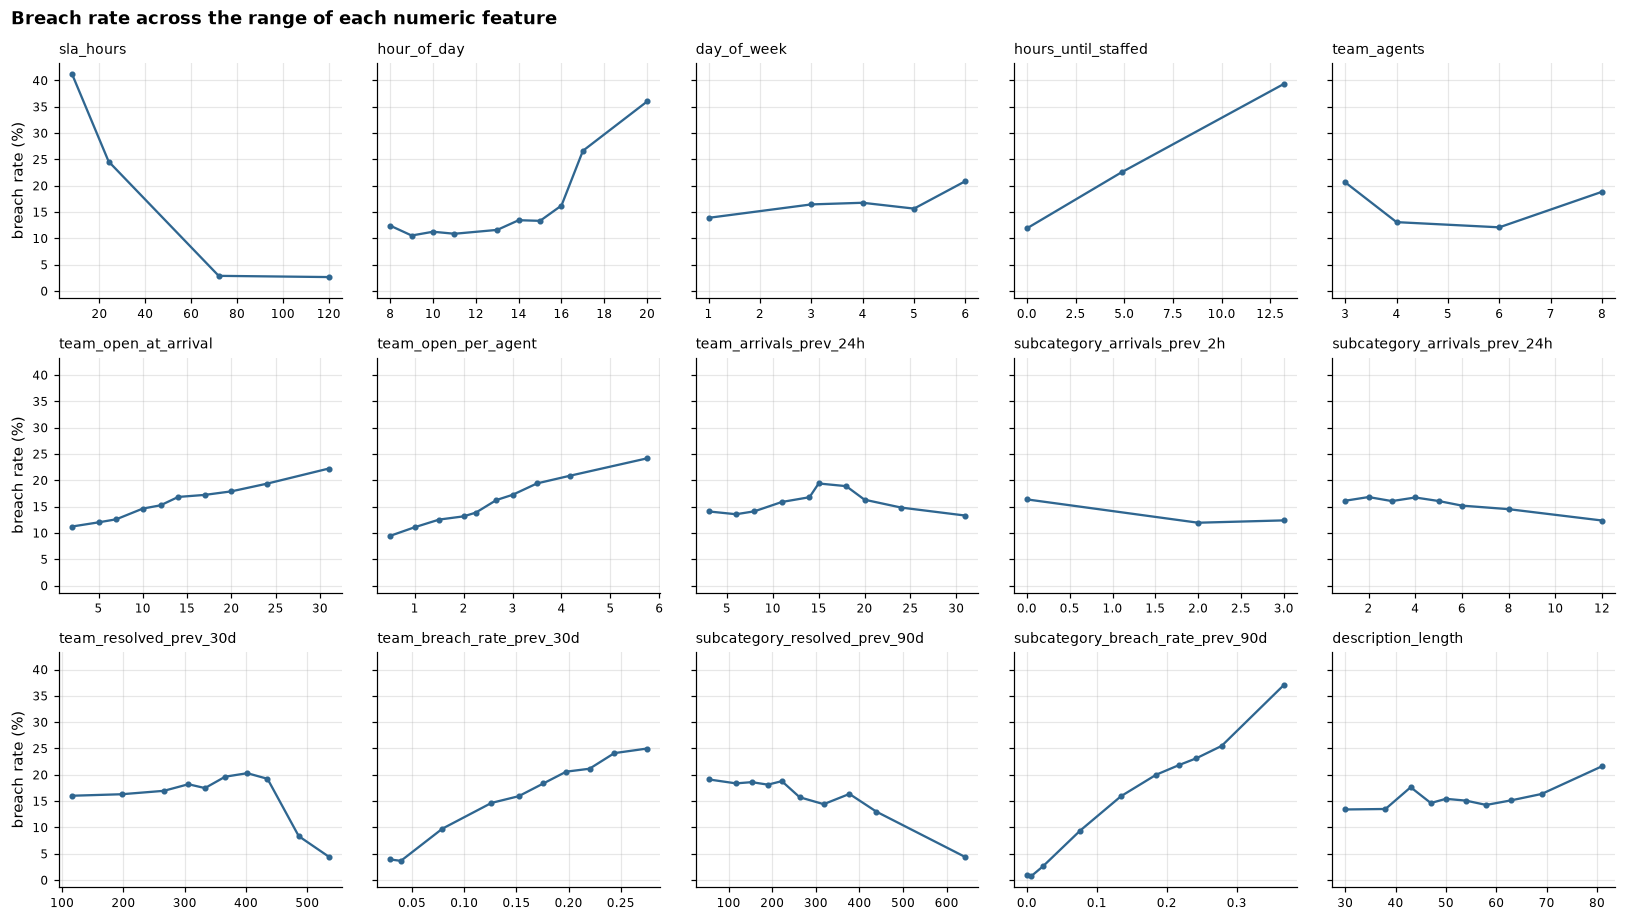

In [6]:
# Breach rate across deciles of each numeric feature. Features with few distinct
# values get fewer bins.
fig, axes = plt.subplots(3, 5, figsize=(15, 8.5), sharey=True)
for ax, name in zip(axes.flat, NUMERIC):
    values = labelled[name].astype("float64")
    bins = pd.qcut(values, 10, duplicates="drop")
    by_bin = labelled.groupby(bins, observed=True)["sla_breached"].mean()
    centres = values.groupby(bins, observed=True).median()
    ax.plot(centres, 100 * by_bin, marker="o", ms=3, color=ACCENT)
    ax.set_title(name, fontsize=9, fontweight="normal")
    ax.tick_params(labelsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("breach rate (%)")
fig.suptitle("Breach rate across the range of each numeric feature", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "02_numeric_feature_signal")

**Strongest single features:**

- `sla_hours` has an AUC of 0.22, which is 0.78 read the other way: the shorter the target, the more likely a breach.
- `subcategory_breach_rate_prev_90d` (0.744) is the strongest positive feature. It is the recent, leakage-safe track record of the same kind of issue, and carries much the same information as `subcategory` itself (Cramer's V 0.33, the highest of the categorical features).
- `team_breach_rate_prev_30d` (0.657), `hour_of_day` (0.625), `hours_until_staffed` (0.623) and `team_open_per_agent` (0.597) follow.

**Count features are mostly stand-ins for identity.** `team_resolved_prev_30d` and `subcategory_resolved_prev_90d` fall sharply at their highest values. Those are Service Desk and password-reset tickets: the busiest team and issue, and the ones least likely to breach. In the same way, `subcategory_arrivals_prev_2h` runs slightly backwards (0.466), because the subcategories with the most recent tickets are the quick ones. A model will separate these from team and subcategory; a single-feature view cannot.

**Little or no signal:** `is_holiday` (0.502), `is_weekend`, `team_arrivals_prev_24h` and `description_length`. The weekend effect already sits in `hours_until_staffed`.

One caution: single-feature AUC ignores interactions. Notebook 01 showed that workload matters much more inside some teams than others, which this view averages away.

## 3. Redundancy

In [7]:
numeric_values = labelled[NUMERIC].astype("float64")
correlation = numeric_values.corr(method="spearman")

pairs = (
    correlation.where(np.triu(np.ones(correlation.shape, dtype=bool), k=1))
    .stack().rename("spearman").reset_index()
)
pairs[pairs["spearman"].abs() >= 0.6].sort_values("spearman", key=abs, ascending=False).round(2)

,level_0,level_1,spearman
81,team_open_at_arrival,team_open_per_agent,0.85
82,team_open_at_arrival,team_arrivals_prev_24h,0.84
97,team_open_per_agent,team_arrivals_prev_24h,0.75
178,team_breach_rate_prev_30d,subcategory_breach_rate_prev_90d,0.65
114,team_arrivals_prev_24h,subcategory_arrivals_prev_24h,0.63


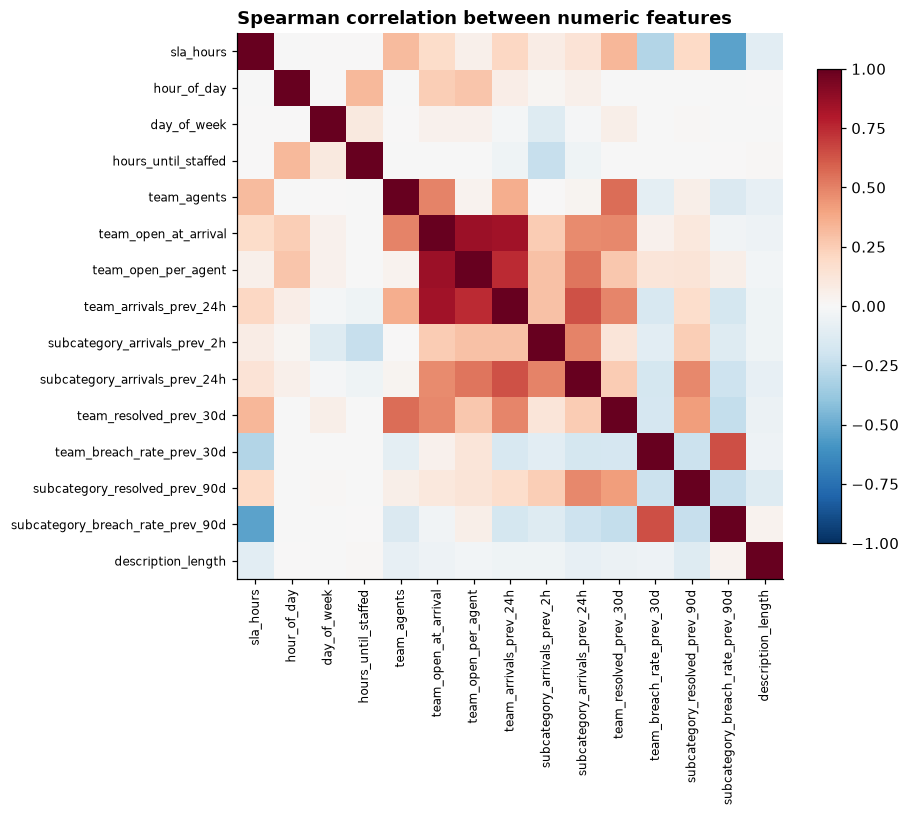

In [8]:
fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERIC)), NUMERIC, rotation=90, fontsize=8)
ax.set_yticks(range(len(NUMERIC)), NUMERIC, fontsize=8)
ax.grid(False)
ax.set_title("Spearman correlation between numeric features")
fig.colorbar(image, ax=ax, shrink=0.8)
save(fig, "02_feature_correlation")

In [9]:
# Categorical features that are completely determined by another feature add
# nothing a model cannot already see.
def determined_share(source, target):
    """Share of rows where `target` equals its most common value within each `source` group."""
    modal = labelled.groupby(source)[target].agg(lambda s: s.mode().iloc[0])
    return (labelled[target] == labelled[source].map(modal)).mean()

pd.DataFrame([
    {"source": "subcategory", "target": t, "determined_pct": round(100 * determined_share("subcategory", t), 1)}
    for t in ["category", "ticket_type", "assigned_team", "priority"]
] + [
    {"source": "assigned_team", "target": "team_agents",
     "determined_pct": round(100 * determined_share("assigned_team", "team_agents"), 1)},
])

,source,target,determined_pct
0,subcategory,category,100.0
1,subcategory,ticket_type,100.0
2,subcategory,assigned_team,95.0
3,subcategory,priority,54.2
4,assigned_team,team_agents,100.0


Three groups of features repeat each other:

- **Backlog:** `team_open_at_arrival`, `team_open_per_agent` and `team_arrivals_prev_24h` are correlated at 0.75-0.85. The per-agent version is the one that is comparable across teams of different sizes.
- **Catalogue fields:** `category` and `ticket_type` are fully determined by `subcategory` (100%), and `team_agents` by `assigned_team`. They add nothing a model with the finer field can't already see.
- **History:** the team and subcategory breach rates are correlated at 0.65, because subcategory largely decides the team.

`assigned_team` matches the subcategory's usual team 95% of the time; the other 5% are the misrouted tickets, which is the information it adds. `priority` is not determined by subcategory (54%), so it is genuinely separate.

Redundancy does not hurt tree models much, but it makes logistic regression coefficients and feature-importance scores hard to read, because the credit is split between near-copies.

## 4. Description features

In [10]:
# Is urgent wording a signal of its own, or just a sign of high priority?
urgency = labelled.pivot_table(index="priority", columns="mentions_urgency", values="sla_breached",
                               aggfunc=["mean", "size"])
urgency.columns = [f"{stat}_{'urgent' if flag else 'not_urgent'}" for stat, flag in urgency.columns]
urgency[["mean_not_urgent", "mean_urgent"]] = (100 * urgency[["mean_not_urgent", "mean_urgent"]]).round(1)
urgency

,mean_not_urgent,mean_urgent,size_not_urgent,size_urgent
priority,,,,
P1,18.8,22.1,574,393
P2,37.1,37.4,6062,1949
P3,16.7,17.1,24216,1280
P4,2.0,1.1,14498,270


In [11]:
# Overall urgency effect versus the effect after holding priority fixed.
overall = labelled.groupby("mentions_urgency")["sla_breached"].mean()
within_priority = (labelled.groupby(["priority", "mentions_urgency"])["sla_breached"].mean()
                   .unstack().diff(axis=1).iloc[:, -1])
weights = labelled["priority"].value_counts(normalize=True)
print(f"urgent minus not urgent, overall: {100 * (overall[True] - overall[False]):.1f} points")
print(f"urgent minus not urgent, averaged within priority: {100 * (within_priority * weights).sum():.1f} points")

urgent minus not urgent, overall: 11.9 points
urgent minus not urgent, averaged within priority: 0.1 points


Urgent wording looks informative overall: tickets that mention urgency breach 11.9 points more often. Within each priority the difference is 0.1 points. Urgent wording is a sign of high priority and nothing more, the same kind of proxy as department in notebook 01. In this data that follows from how descriptions were generated, since urgency phrases depend only on priority. With real text it would be worth checking again, because people sometimes write "urgent" when the priority field is wrong.

`description_length` is weak (AUC 0.531), and its small upward trend is more likely to reflect which templates belong to which subcategories than anything about urgency. Any real text features, such as TF-IDF, will be tested as a separate experiment against the structured-feature model.

## 5. Missing history at the start

In [12]:
history = ["team_breach_rate_prev_30d", "subcategory_breach_rate_prev_90d"]
by_month = labelled.groupby(labelled["created_at"].dt.to_period("M"))
start = pd.DataFrame({
    "labelled": by_month.size(),
    **{f"{h}_missing": by_month[h].apply(lambda s: s.isna().sum()) for h in history},
    "median_subcategory_resolved_prev_90d": by_month["subcategory_resolved_prev_90d"].median(),
}).head(5)
start

,labelled,team_breach_rate_prev_30d_missing,subcategory_breach_rate_prev_90d_missing,median_subcategory_resolved_prev_90d
created_at,,,,
2024-01,2567,19,44,44.0
2024-02,2161,0,0,144.0
2024-03,2162,0,0,238.0
2024-04,2383,0,0,298.0
2024-05,1730,0,0,284.0


All missing history values fall in January 2024, the first month of data. From February every ticket has both history rates, and the subcategory rate is based on a median of 144 resolved tickets, rising to about 300 by April.

Starting the modeling window on 2024-02-01 removes the missing values instead of inventing them, at the cost of 2,567 tickets (5% of the labelled data). The model pipeline will still impute these features with a missing-value flag, so that a new team or subcategory in production does not break it.

## 6. Train and test periods

In [13]:
window = labelled[(labelled["created_at"] >= MODEL_START) & (labelled["created_at"] < MODEL_END)].copy()
window["split"] = np.where(window["created_at"] < TEST_START, "train", "test")
train, test = window[window["split"] == "train"], window[window["split"] == "test"]

difference, low, high = difference_interval(int(test["sla_breached"].sum()), len(test),
                                            int(train["sla_breached"].sum()), len(train))
summary = window.groupby("split").agg(first=("created_at", "min"), last=("created_at", "max"),
                                      tickets=("ticket_id", "size"), breach_rate=("sla_breached", "mean"))
print(f"excluded before {MODEL_START:%Y-%m-%d}: {(labelled['created_at'] < MODEL_START).sum():,}; "
      f"excluded from {MODEL_END:%Y-%m-%d}: {(labelled['created_at'] >= MODEL_END).sum():,}")
print(f"test minus train breach rate: {100 * difference:.1f} points (95% interval {100 * low:.1f} to {100 * high:.1f})")
summary.assign(breach_rate=lambda d: (100 * d["breach_rate"]).round(1)).loc[["train", "test"]]

excluded before 2024-02-01: 2,567; excluded from 2025-12-18: 502
test minus train breach rate: 0.1 points (95% interval -0.7 to 0.8)


,first,last,tickets,breach_rate
split,,,,
train,2024-02-01 01:57:41,2025-06-30 22:16:54,34426,15.6
test,2025-07-01 00:02:51,2025-12-17 22:55:21,11747,15.7


In [14]:
# Population stability index: how far each feature's distribution moved from train to test.
drift = pd.DataFrame([
    {"feature": f, "psi": population_stability_index(train[f], test[f])}
    for f in NUMERIC + BOOLEAN + CATEGORICAL
]).sort_values("psi", ascending=False).reset_index(drop=True)
drift["reading"] = pd.cut(drift["psi"], [-np.inf, 0.1, 0.25, np.inf], labels=["stable", "moderate", "large"])
drift.round(3).head(12)

,feature,psi,reading
0,team_breach_rate_prev_30d,0.163,moderate
1,subcategory_breach_rate_prev_90d,0.084,stable
2,team_resolved_prev_30d,0.078,stable
3,academic_period,0.074,stable
4,subcategory_resolved_prev_90d,0.022,stable
5,team_open_per_agent,0.011,stable
6,team_arrivals_prev_24h,0.005,stable
7,subcategory_arrivals_prev_24h,0.005,stable
8,subcategory,0.004,stable
9,is_holiday,0.004,stable


In [15]:
period_mix = pd.crosstab(window["split"], window["academic_period"], normalize="index").loc[["train", "test"]]
(100 * period_mix).round(1)

academic_period,regular,semester_start,summer,winter_break
split,,,,
train,70.5,9.1,19.2,1.2
test,68.8,13.2,18.0,0.0


**The base rate is stable:** 15.6% in training and 15.7% in test (difference 0.1 points, interval -0.7 to 0.8). Breach prediction in the test period is neither easier nor harder because of the label rate.

**Feature drift is small.** Every feature has a PSI below 0.1 except `team_breach_rate_prev_30d` (0.163, moderate). Its mean barely changes (15.6% to 15.2%) and each team's average moves by under 2 points. The PSI comes from the feature's lumpy shape: values cluster at each team's level, so small per-team shifts move tickets across the decile boundaries. The training period also contains the extremes, from the Desktop Support staffing cut and the phishing campaign. Rolling-history features are designed to follow current conditions, so they are the ones to monitor once a model is in use.

**The calendar mix differs.** The test period has more semester-start days (13.2% against 9.1%) and no winter break. Test results will lean slightly toward the busier parts of the year.

In [16]:
# Time-ordered validation folds inside the training period: each fold trains on
# everything before a quarter and validates on that quarter.
fold_starts = pd.to_datetime(["2024-10-01", "2025-01-01", "2025-04-01"])
fold_ends = list(fold_starts[1:]) + [TEST_START]
folds = pd.DataFrame([
    {"fold": i + 1,
     "train_until": start.date(),
     "validate": f"{start:%Y-%m-%d} to {(end - pd.Timedelta(days=1)):%Y-%m-%d}",
     "train_tickets": int((train["created_at"] < start).sum()),
     "validate_tickets": int(train["created_at"].between(start, end, inclusive="left").sum()),
     "validate_breach_pct": round(100 * train.loc[train["created_at"].between(start, end, inclusive="left"),
                                                   "sla_breached"].mean(), 1)}
    for i, (start, end) in enumerate(zip(fold_starts, fold_ends))
])
folds

,fold,train_until,validate,train_tickets,validate_tickets,validate_breach_pct
0,1,2024-10-01,2024-10-01 to 2024-12-31,15804,6306,15.4
1,2,2025-01-01,2025-01-01 to 2025-03-31,22110,7059,16.5
2,3,2025-04-01,2025-04-01 to 2025-06-30,29169,5257,15.7


Three time-ordered folds inside the training period, each training on everything before a quarter and validating on that quarter. Validation breach rates are 15.4-16.5%. Fold 3 validates on April-June 2025, the Desktop Support staffing cut, which gives a natural check of how a model trained before the cut handles it.

## Decision record for Phase 5

These choices are fixed before any model is trained. Changing one later needs a written reason.

**1. Target and population.** `sla_breached` for resolved tickets created from 2024-02-01 up to 2025-12-17. January 2024 is excluded as a warm-up month for the history features (2,567 tickets); the final 14 days are excluded because many of their outcomes are not known yet (502 resolved tickets).

**2. Split.** Train: 2024-02-01 to 2025-06-30 (34,426 tickets, 15.6% breached). Test: 2025-07-01 to 2025-12-17 (11,747 tickets, 15.7%). The test set is used once, for the final evaluation.

**3. Validation.** Model and threshold choices use the three expanding-window folds above (validating on Q4 2024, Q1 2025 and Q2 2025), never the test set.

**4. Features.**

| Use | Features |
|---|---|
| Categorical | `priority`, `subcategory`, `assigned_team`, `academic_period`, `requester_type`, `channel` |
| Numeric | `sla_hours`, `hours_until_staffed`, `hour_of_day`, `day_of_week`, `is_weekend`, `is_holiday`, `team_open_per_agent`, `subcategory_arrivals_prev_2h`, `subcategory_arrivals_prev_24h`, `team_breach_rate_prev_30d`, `team_resolved_prev_30d`, `subcategory_breach_rate_prev_90d`, `subcategory_resolved_prev_90d` |

| Left out | Reason |
|---|---|
| `category`, `ticket_type` | Fully determined by `subcategory` |
| `team_agents` | Fully determined by `assigned_team` |
| `team_open_at_arrival`, `team_arrivals_prev_24h` | Near-copies of `team_open_per_agent` (0.84-0.85) |
| `department` | Its differences are explained by issue mix (notebook 01); no signal of its own |
| `mentions_urgency` | No effect once priority is known (0.1 points) |
| `description_length`, raw `description` | Weak and template-driven; text is a separate experiment |

**5. Missing values.** None in the modeling window. The pipeline still imputes history features with the training median plus a missing-value flag, so unseen teams or subcategories do not break it.

**6. Encoding.** One-hot encoding for categorical features. Scaling for logistic regression only. Every transformation is fitted inside the training data of each fold.

**7. Metrics.**

- **Primary:** average precision (area under the precision-recall curve). With 15.7% positives and a model meant to rank tickets for attention, it reflects performance on the breaches themselves better than ROC-AUC.
- **Also reported:** ROC-AUC; precision, recall and F1 at the operating threshold; the confusion matrix; Brier score and a calibration curve, because a risk percentage shown on a dashboard should mean what it says.
- **Uncertainty:** bootstrap 95% intervals for test metrics.
- **Breakdown:** the same metrics by team, so a good overall score cannot hide a team the model fails.

**8. Operating threshold.** Chosen on the validation folds. The main operating point assumes the desk can review the riskiest 10% of new tickets; this capacity is an assumption, not a measured number, and results at other capacities will be shown alongside.

**9. Baselines a model must beat.**

- Never predicting a breach: average precision equal to the base rate (about 0.157), ROC-AUC 0.5.
- The single feature `subcategory_breach_rate_prev_90d`: ROC-AUC 0.744 on all labelled data.
- Logistic regression on the chosen features, as the simple model the others have to improve on.

**10. Models.** Logistic regression, random forest and XGBoost, as in the project requirements. The interactions found in notebook 01 (priority with arrival window, team with workload) suggest the tree-based models should help, but that is a prediction to test, not an assumption.

**11. Monitoring.** Once a model is in use, PSI on the rolling-history features, starting with `team_breach_rate_prev_30d`, the one feature that moved between training and test here.